In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re,string


In [2]:
df = pd.read_csv(r'fake_and_real_news.csv')

In [47]:
df

,Text,label
0,Top Trump Surrogate BRUTALLY Stabs Him In The...,Fake
1,U.S. conservative leader optimistic of common ...,Real
2,"Trump proposes U.S. tax overhaul, stirs concer...",Real
3,Court Forces Ohio To Allow Millions Of Illega...,Fake
4,Democrats say Trump agrees to work on immigrat...,Real
...,...,...
9895,Wikileaks Admits To Screwing Up IMMENSELY Wit...,Fake
9896,Trump consults Republican senators on Fed chie...,Real
9897,Trump lawyers say judge lacks jurisdiction for...,Real
9898,WATCH: Right-Wing Pastor Falsely Credits Trum...,Fake


In [39]:
df.isnull().sum()

Text     0
label    0
dtype: int64

In [5]:
df.describe()

,Text,label
count,9900,9900
unique,9865,2
top,Highlights: The Trump presidency on April 13 a...,Fake
freq,8,5000


In [48]:
df['label'] = df['label'].map({'Fake':0,'Real':1})

In [7]:
df

,Text,label
0,Top Trump Surrogate BRUTALLY Stabs Him In The...,0
1,U.S. conservative leader optimistic of common ...,1
2,"Trump proposes U.S. tax overhaul, stirs concer...",1
3,Court Forces Ohio To Allow Millions Of Illega...,0
4,Democrats say Trump agrees to work on immigrat...,1
...,...,...
9895,Wikileaks Admits To Screwing Up IMMENSELY Wit...,0
9896,Trump consults Republican senators on Fed chie...,1
9897,Trump lawyers say judge lacks jurisdiction for...,1
9898,WATCH: Right-Wing Pastor Falsely Credits Trum...,0


<Axes: xlabel='label', ylabel='count'>

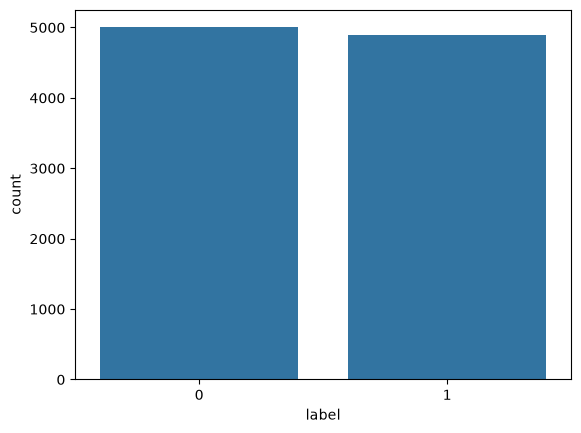

In [8]:
sns.countplot(x=df['label'])

In [9]:
def wordopt(text):
    text = text.lower()
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'\[.*?\]', '', text)
    text = re.sub(f"[{re.escape(string.punctuation)}]", "", text)
    text = re.sub(r'\w*\d\w*', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

In [10]:
df['Text'] = df['Text'].apply(wordopt)
df

,Text,label
0,top trump surrogate brutally stabs him in the ...,0
1,us conservative leader optimistic of common gr...,1
2,trump proposes us tax overhaul stirs concerns ...,1
3,court forces ohio to allow millions of illegal...,0
4,democrats say trump agrees to work on immigrat...,1
...,...,...
9895,wikileaks admits to screwing up immensely with...,0
9896,trump consults republican senators on fed chie...,1
9897,trump lawyers say judge lacks jurisdiction for...,1
9898,watch rightwing pastor falsely credits trump f...,0


In [49]:
x = df['Text']
y = df['label']

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
tf = TfidfVectorizer(dtype= np.float32)
x_vec = tf.fit_transform(x).toarray()

In [50]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,random_state=42,test_size=0.2)

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

In [15]:
'''def Model_train(x_train,x_test,y_train,y_test):
    models={
    'LR':LogisticRegression(),
    'RF':RandomForestClassifier(n_estimators=50,n_jobs=-1,max_depth=30),
    'KNN':KNeighborsClassifier(),
    'XGB':XGBClassifier(n_estimators=50,n_jobs=-1),
    
    }
    result=[]
    for name,model in models.items():
        model.fit(x_train,y_train)
        y_pred = model.predict(x_test)
        score = accuracy_score(y_test,y_pred)
        print(score)
        result.append({
            'model_name':name,
            'model_score':score
        })
    new_result = pd.DataFrame(result)
'''
        

"def Model_train(x_train,x_test,y_train,y_test):\n    models={\n    'LR':LogisticRegression(),\n    'RF':RandomForestClassifier(n_estimators=50,n_jobs=-1,max_depth=30),\n    'KNN':KNeighborsClassifier(),\n    'XGB':XGBClassifier(n_estimators=50,n_jobs=-1),\n\n    }\n    result=[]\n    for name,model in models.items():\n        model.fit(x_train,y_train)\n        y_pred = model.predict(x_test)\n        score = accuracy_score(y_test,y_pred)\n        print(score)\n        result.append({\n            'model_name':name,\n            'model_score':score\n        })\n    new_result = pd.DataFrame(result)\n"

In [16]:
#Model_train(x_train,x_test,y_train,y_test)

In [ ]:
'''from sklearn.model_selection import RandomizedSearchCV

best_param = {
    'n_estimators' : [30,40,50],
    'max_depth' : [3,5,8],
    'learning_rate' : [0.1,0.3,0.5],
}

cv = RandomizedSearchCV(
    XGBClassifier(random_state=42),
    param_distributions=best_param,
    n_iter = 10,
    scoring = 'accuracy',
    cv = 3,
    random_state = 49,
)

cv.fit(x_train,y_train)
print(f"Best Parameter : {cv.best_params_}")'''

ValueError: Invalid format specifier ' [30,40,50],
    'max_depth' : [3,5,8],
    'learning_rate' : [0.1,0.3,0.5],
' for object of type 'str'

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report

param_grid = {
    'C': [0.01, 0.1, 1, 10],   # inverse regularization strength
    'penalty': ['l1', 'l2'],
    'class_weight': [None, 'balanced'],
}

grid = GridSearchCV(
    LogisticRegression(solver='liblinear', max_iter=100, random_state=42),
    param_grid=param_grid,
    scoring='f1',
    cv=3,
    n_jobs=-1,
    verbose=1,
)

grid.fit(x_train, y_train)

print(f"Best Parameters: {grid.best_params_}")
print(f"Best CV F1:      {grid.best_score_:.4f}")

best_model = grid.best_estimator_   # already refit on the full training set
print(classification_report(y_test, best_model.predict(x_test)))

Fitting 3 folds for each of 16 candidates, totalling 48 fits


c:\Project\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Project\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Best Parameters: {'C': 10, 'class_weight': None, 'penalty': 'l1'}
Best CV F1:      0.9978
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       973
           1       1.00      1.00      1.00      1007

    accuracy                           1.00      1980
   macro avg       1.00      1.00      1.00      1980
weighted avg       1.00      1.00      1.00      1980



In [22]:
lr = LogisticRegression(C= 10, class_weight = None, l1_ratio=0)
lr.fit(x_train,y_train)
y_pred = lr.predict(x_test)

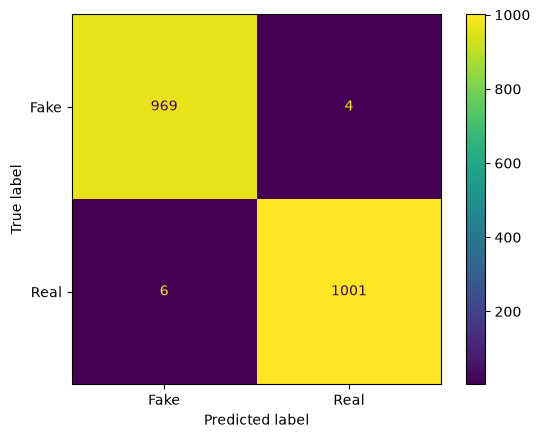

In [26]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
cm = confusion_matrix(y_test,y_pred)
disp = ConfusionMatrixDisplay(cm,display_labels=['Fake','Real'])
disp.plot()

In [30]:
x_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(7920, 81533), dtype=float32)

In [35]:
y_train = np.array(y_train).reshape(7920,1)
y_train

array([[1],
       [1],
       [1],
       ...,
       [0],
       [1],
       [1]], shape=(7920, 1))

In [51]:
from sklearn.pipeline import Pipeline
pipe = Pipeline([('vectorizer',TfidfVectorizer(preprocessor=wordopt)),('classifier',LogisticRegression())])
pipe.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('vectorizer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",<function wor...0029177C23B60>
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None


In [52]:
pipe.predict(['donald trump was murdered at NY'])

array([0])

In [54]:
pipe.predict(['Government is adding a new policy today'])

array([1])

In [55]:
import joblib
joblib.dump(pipe,'news.pkl')

['news.pkl']